# Phase 7 — Backtest of the setup score

**Purpose.** The allocator (Phase 5) and the daily report (Phase 6) rank
stocks by the setup score. Nobody has checked that the score works. This
notebook checks it against five years of history.

**Four hypotheses.** Each is a claim the lab has been making without proof.

| | Claim | Test |
|---|---|---|
| H1 | The scan filters pick better stocks | compare stocks that pass with stocks that do not |
| H2 | A higher score means a better trade | compare score groups; rank correlation |
| H3 | Each part of the score points the right way | rank correlation of each part |
| H4 | The regime gate improves results | compare gate open with gate closed |

**Method, with no look-ahead.** Step through history every 5 trading days.
On each date cut the data at that date, run the scanner's own code, then
record what happened afterwards: forward returns, and the result in R of a
trade run by your rules.

**The trade rules used.** Enter at the next day's open. Stop 0.5 ADR below
entry. At +3R sell one third and move the stop to breakeven. From the third
day, or after the trim, exit on a close below the 9-day EMA. Maximum 40 days.

**Read this first.** Three weaknesses make the absolute numbers too good:
the universe is today's hand-picked list of survivors; entries are at the
open, not at an intraday breakout; no costs or slippage. Comparisons
between groups are more trustworthy than levels. Study tool, not advice.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

import lab_style as ls
import backtest as bt

ls.use_lab_style()
pd.set_option("display.width", 200)

In [2]:
# ============================================================
# KEY IN HERE
# ============================================================
REFRESH = False     # True = download 5 years of fresh history (needs internet)
STEP    = 5         # trading days between scan dates
STOP    = "0.5"     # stop distance used for the R results: "0.5" or "1.0" ADR
OUTCOME = "fwd_10"  # forward return used for rank correlation: fwd_5, fwd_10, fwd_20

R_COL = f"R_{STOP}"

## Step 1 — Build the panel

One row per (scan date, stock) for every stock that passes the price,
liquidity and ADR filters on that date.

In [3]:
prices = bt.load_history(refresh=REFRESH)
close = prices["Close"]
print(f"History: {close.shape[0]} days x {close.shape[1]} tickers, "
      f"{close.index[0].date()} to {close.index[-1].date()}")

panel = bt.build_panel(prices, step=STEP)
dates = panel.index.get_level_values("date")
passed = panel[panel["passed"]]

print(f"Scan dates: {dates.nunique()}  ({dates.min().date()} to {dates.max().date()})")
print(f"Rows (high-ADR stocks on a scan date): {len(panel):,}")
print(f"  of which leaders (momentum rank ≥ 90): {int(panel['f_leader'].sum()):,}")
print(f"  of which pass every filter           : {len(passed):,}")
print(f"Scan dates with the regime gate open   : "
      f"{100 * panel.groupby(level='date')['gate'].first().mean():.0f}%")

History: 1255 days x 182 tickers, 2021-11-15 to 2026-11-13


Scan dates: 221  (2022-05-23 to 2026-10-12)
Rows (high-ADR stocks on a scan date): 12,830
  of which leaders (momentum rank ≥ 90): 4,727
  of which pass every filter           : 2,977
Scan dates with the regime gate open   : 53%


## Step 2 — What the simulated trades look like

Every stock that passed every filter, traded by the rules above. The spike
at +1R is trades that reached +3R, banked one third, and were then stopped
at breakeven on the rest.

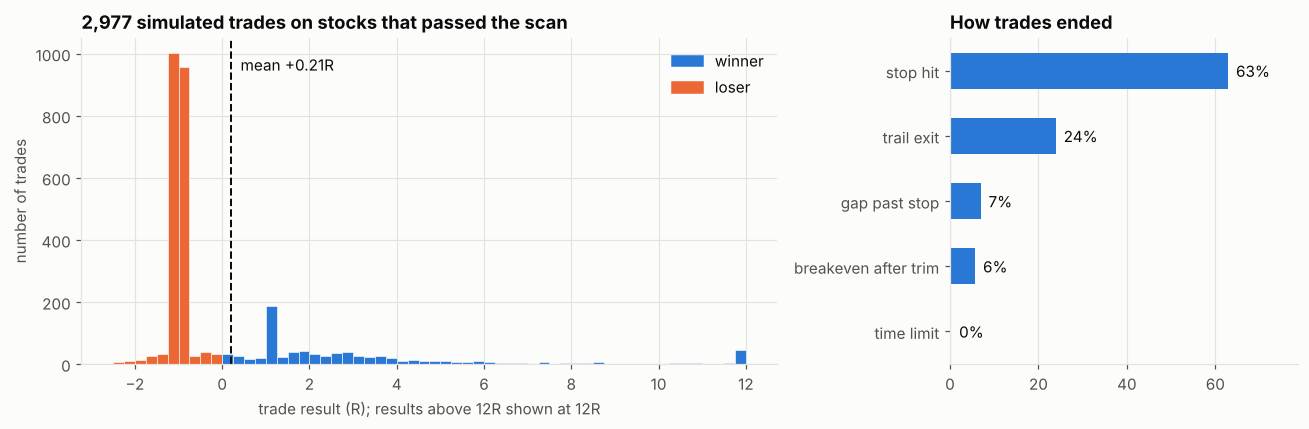

{'trades': 2977.0, 'win rate %': 27.41, 'avg winner R': 3.49, 'avg loser R': -1.03, 'expectancy R': 0.21, 'median R': -1.0}


In [4]:
R = passed[R_COL].dropna()
stats = bt.trade_stats(R)
exits = passed[f"exit_{STOP}"].value_counts(normalize=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [2, 1]})
ax = axes[0]
bins = np.arange(-2.5, 12.25, 0.25)
_, edges, patches = ax.hist(R.clip(upper=12), bins=bins, color=ls.BLUE,
                            edgecolor=ls.SURFACE, linewidth=0.4)
for patch, left in zip(patches, edges[:-1]):
    if left < 0:
        patch.set_facecolor(ls.ORANGE)
ax.axvline(R.mean(), color=ls.TEXT, lw=1.3, ls="--")
ax.annotate(f"mean {R.mean():+.2f}R", (R.mean(), ax.get_ylim()[1] * 0.9),
            textcoords="offset points", xytext=(6, 0), color=ls.TEXT)
ax.set_xlabel("trade result (R); results above 12R shown at 12R")
ax.set_ylabel("number of trades")
ax.set_title(f"{len(R):,} simulated trades on stocks that passed the scan")
ax.legend(handles=[Patch(color=ls.BLUE, label="winner"), Patch(color=ls.ORANGE, label="loser")],
          loc="upper right")

ax = axes[1]
labels = {"stop": "stop hit", "trail": "trail exit", "gap": "gap past stop",
          "breakeven": "breakeven after trim", "time": "time limit"}
order = list(exits.index)[::-1]
ax.barh([labels.get(k, k) for k in order], 100 * exits[order], color=ls.BLUE, height=0.55)
for y, k in enumerate(order):
    ax.annotate(f"{100 * exits[k]:.0f}%", (100 * exits[k], y), textcoords="offset points",
                xytext=(5, -4), color=ls.TEXT)
ax.set_xlim(0, 100 * exits.max() * 1.25); ax.grid(axis="y", visible=False)
ax.set_title("How trades ended")
plt.tight_layout(); plt.show()

print({k: round(float(v), 2) for k, v in stats.items()})

## Step 3 — The backtest edge against the borrowed edge

Phases 1 to 3 start from a borrowed 23% win rate and 8R average winner.
The same rules on this universe give the numbers below.

In [5]:
borrowed = {"win rate %": 23.0, "avg winner R": 8.0, "avg loser R": -1.0,
            "expectancy R": 0.23 * 8 - 0.77}
compare = pd.DataFrame({"borrowed (Luk / Qullamaggie)": borrowed,
                        f"backtest, stop {STOP} ADR": {k: stats[k] for k in borrowed}}).T
print(compare.round(2).to_string())

                              win rate %  avg winner R  avg loser R  expectancy R
borrowed (Luk / Qullamaggie)       23.00          8.00        -1.00          1.07
backtest, stop 0.5 ADR             27.41          3.49        -1.03          0.21


The win rate is similar. The average winner is far smaller, so the
expectancy is a fraction of the borrowed one, and that is before the
biases listed above are removed.

## Step 4 — H1: do the filters pick better stocks?

Expectancy in R for four nested groups. The bars' whiskers are 90%
bootstrap intervals, resampling whole scan dates (trades opened on the
same day are not independent).

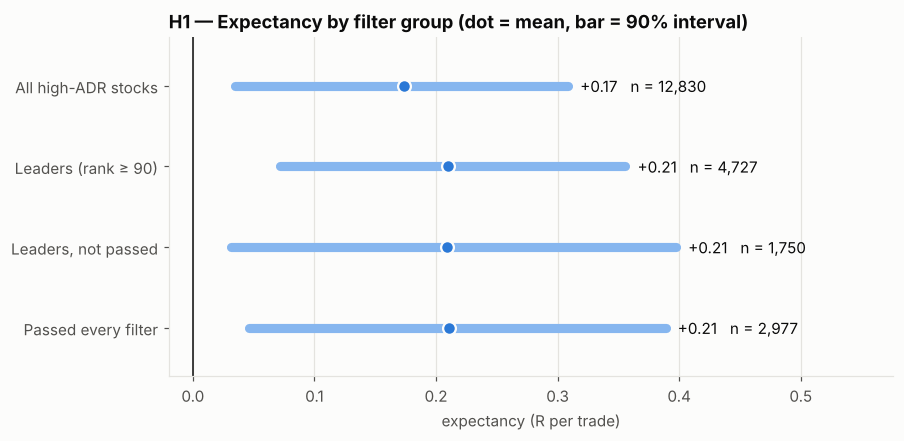

                      mean     lo     hi   trades   win %  fwd_10 %
All high-ADR stocks  0.174  0.034  0.309  12830.0  29.790     1.711
Leaders (rank ≥ 90)  0.210  0.071  0.356   4727.0  28.877     2.242
Leaders, not passed  0.209  0.031  0.397   1750.0  31.371     1.956
Passed every filter  0.211  0.046  0.389   2977.0  27.410     2.409



Passed minus not passed: +0.048R, 90% interval -0.185 to +0.282


In [6]:
def interval(frame, column=R_COL):
    boot = bt.bootstrap_by_date(frame, column, draws=1500)
    return frame[column].mean(), np.percentile(boot, 5), np.percentile(boot, 95)

groups = {
    "All high-ADR stocks": panel,
    "Leaders (rank ≥ 90)": panel[panel["f_leader"]],
    "Leaders, not passed": panel[panel["f_leader"] & ~panel["passed"]],
    "Passed every filter": passed,
}
h1 = pd.DataFrame({name: dict(zip(["mean", "lo", "hi"], interval(g)), trades=len(g),
                              **{"win %": 100 * np.mean(g[R_COL] > 0),
                                 f"{OUTCOME} %": 100 * g[OUTCOME].mean()})
                   for name, g in groups.items()}).T

def interval_chart(table, title, xlabel="expectancy (R per trade)"):
    fig, ax = plt.subplots(figsize=(8.5, 0.6 * len(table) + 1.6))
    names = list(table.index)[::-1]
    for y, name in enumerate(names):
        row = table.loc[name]
        ax.plot([row["lo"], row["hi"]], [y, y], color=ls.BLUE_BAND_INNER, lw=6,
                solid_capstyle="round")
        ax.scatter([row["mean"]], [y], s=70, color=ls.BLUE, edgecolor=ls.SURFACE,
                   linewidth=1.5, zorder=3)
        ax.annotate(f"{row['mean']:+.2f}   n = {int(row['trades']):,}", (row["hi"], y),
                    textcoords="offset points", xytext=(8, -4), color=ls.TEXT)
    ax.axvline(0, color=ls.TEXT, lw=1)
    ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
    ax.set_ylim(-0.6, len(names) - 0.4); ax.grid(axis="y", visible=False)
    span = table["hi"].max() - min(table["lo"].min(), 0)
    ax.set_xlim(min(table["lo"].min(), 0) - 0.05 * span, table["hi"].max() + 0.45 * span)
    ax.set_xlabel(xlabel); ax.set_title(title)
    plt.show()

interval_chart(h1, "H1 — Expectancy by filter group (dot = mean, bar = 90% interval)")
print(h1.round(3).to_string())

d_h1 = bt.bootstrap_diff(passed, panel[~panel["passed"]], R_COL, draws=1500)
h1_lo, h1_hi = np.percentile(d_h1, [5, 95])
print(f"\nPassed minus not passed: {d_h1.mean():+.3f}R, 90% interval {h1_lo:+.3f} to {h1_hi:+.3f}")

## Step 5 — H2: does a higher score mean a better trade?

On each scan date the stocks that passed are split into three equal groups
by score: low, mid, high. If the score works, expectancy rises from low to
high.

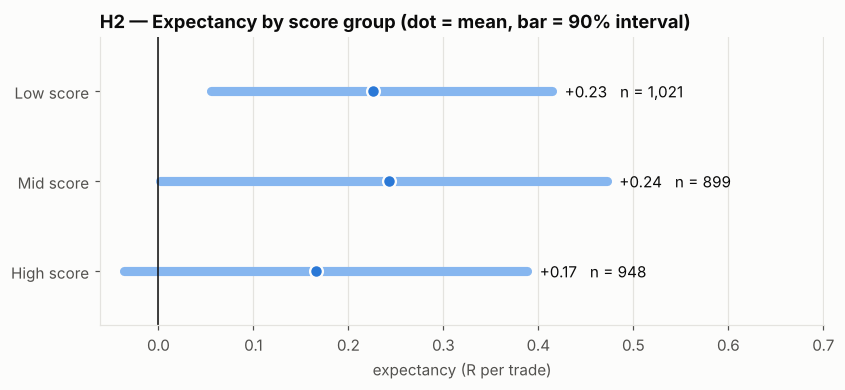

             mean     lo     hi  trades   win %  fwd_10 %  avg score
Low score   0.226  0.055  0.415  1021.0  27.816     2.290     48.789
Mid score   0.243  0.002  0.472   899.0  26.808     2.393     61.384
High score  0.166 -0.036  0.389   948.0  27.321     2.134     73.244



High minus low: -0.056R, 90% interval -0.334 to +0.233


In [7]:
def thirds(s):
    if len(s) < 6:
        return pd.Series(np.nan, index=s.index)
    return pd.qcut(s.rank(method="first"), 3, labels=["Low score", "Mid score", "High score"])

scored = passed.copy()
scored["group"] = scored.groupby(level="date")["score"].transform(thirds)
scored = scored.dropna(subset=["group"])

h2 = pd.DataFrame({name: dict(zip(["mean", "lo", "hi"], interval(scored[scored["group"] == name])),
                              trades=int((scored["group"] == name).sum()),
                              **{"win %": 100 * np.mean(scored.loc[scored["group"] == name, R_COL] > 0),
                                 f"{OUTCOME} %": 100 * scored.loc[scored["group"] == name, OUTCOME].mean(),
                                 "avg score": scored.loc[scored["group"] == name, "score"].mean()})
                   for name in ["Low score", "Mid score", "High score"]}).T

interval_chart(h2, "H2 — Expectancy by score group (dot = mean, bar = 90% interval)")
print(h2.round(3).to_string())

d_h2 = bt.bootstrap_diff(scored[scored["group"] == "High score"],
                         scored[scored["group"] == "Low score"], R_COL, draws=1500)
h2_lo, h2_hi = np.percentile(d_h2, [5, 95])
print(f"\nHigh minus low: {d_h2.mean():+.3f}R, 90% interval {h2_lo:+.3f} to {h2_hi:+.3f}")

### Rank correlation (information coefficient)

On each scan date, rank the passed stocks by score and by what happened
next, and correlate the two rankings. This is the **information
coefficient (IC)**. Zero means the score knows nothing. A useful signal
has a small positive IC on most dates. The chart adds the ICs up over
time: a rising line means the score helps, a flat line means it does not,
a falling line means it points the wrong way.

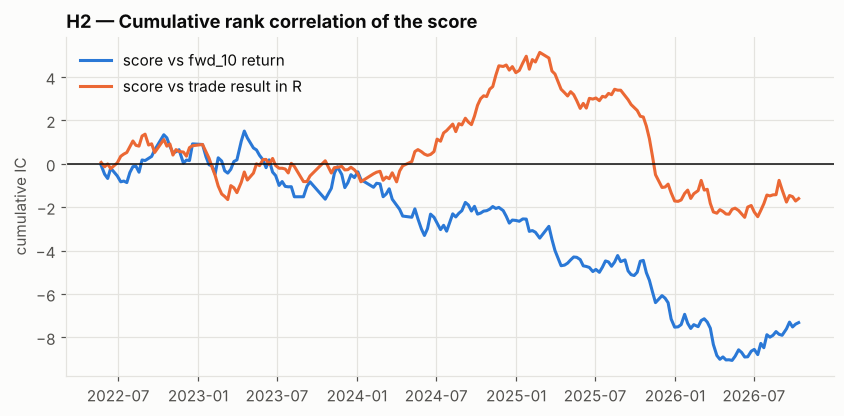

                 dates  mean IC  t-stat  % dates positive
score vs fwd_10  198.0   -0.037  -1.584            44.444
score vs R_0.5   198.0   -0.008  -0.367            48.485

A t-stat beyond ±2 is the usual bar. Overlapping scan dates make the true bar higher.


In [8]:
ic_ret = bt.rank_ic(passed, "score", OUTCOME)
ic_R = bt.rank_ic(passed, "score", R_COL)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(ic_ret.index, ic_ret.cumsum(), color=ls.BLUE, label=f"score vs {OUTCOME} return")
ax.plot(ic_R.index, ic_R.cumsum(), color=ls.ORANGE, label="score vs trade result in R")
ax.axhline(0, color=ls.TEXT, lw=1)
ax.set_ylabel("cumulative IC"); ax.set_title("H2 — Cumulative rank correlation of the score")
ax.legend(loc="best")
plt.show()

ic_table = pd.DataFrame({f"score vs {OUTCOME}": bt.ic_summary(ic_ret),
                         f"score vs {R_COL}": bt.ic_summary(ic_R)}).T
print(ic_table.round(3).to_string())
print("\nA t-stat beyond ±2 is the usual bar. Overlapping scan dates make the "
      "true bar higher.")

## Step 6 — H3: does each part of the score point the right way?

The score assumes: higher momentum rank is better, **lower** tightness is
better, **lower** volume ratio is better, **smaller** extension is better.
The table gives the IC of each raw input, among the stocks that passed.
The sign the score expects is shown beside it.

              score expects IC vs fwd_10 t-stat  IC vs R_0.5 t-stat agrees
mom_rank   higher is better       -0.021  -0.930      +0.027 +1.105  False
tightness   lower is better       +0.040  +1.655      +0.027 +1.231  False
vol_dryup   lower is better       +0.044  +1.899      +0.011 +0.510  False
ext_adr     lower is better       +0.015  +0.656      -0.005 -0.230  False


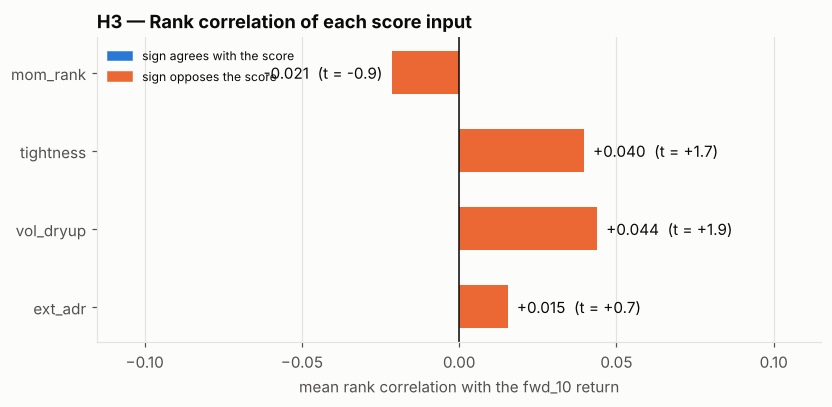

In [9]:
expected = {"mom_rank": +1, "tightness": -1, "vol_dryup": -1, "ext_adr": -1}
passed_abs = passed.assign(ext_adr=passed["ext_adr"].abs())
rows = {}
for part, sign in expected.items():
    s_ret = bt.ic_summary(bt.rank_ic(passed_abs, part, OUTCOME))
    s_R = bt.ic_summary(bt.rank_ic(passed_abs, part, R_COL))
    rows[part] = {"score expects": "higher is better" if sign > 0 else "lower is better",
                  f"IC vs {OUTCOME}": s_ret["mean IC"], "t-stat ": s_ret["t-stat"],
                  f"IC vs {R_COL}": s_R["mean IC"], "t-stat": s_R["t-stat"],
                  "agrees": bool(np.sign(s_ret["mean IC"]) == sign)}
h3 = pd.DataFrame(rows).T
print(h3.to_string(float_format=lambda v: f"{v:+.3f}"))

fig, ax = plt.subplots(figsize=(8.5, 3.6))
parts = list(expected)[::-1]
vals = [float(h3.loc[p, f"IC vs {OUTCOME}"]) for p in parts]
colors = [ls.BLUE if np.sign(v) == expected[p] else ls.ORANGE for p, v in zip(parts, vals)]
ax.barh(parts, vals, color=colors, height=0.55)
for y, (p, v) in enumerate(zip(parts, vals)):
    ax.annotate(f"{v:+.3f}  (t = {float(h3.loc[p, 't-stat ']):+.1f})", (v, y),
                textcoords="offset points", xytext=(6 if v >= 0 else -6, -4),
                ha="left" if v >= 0 else "right", color=ls.TEXT)
ax.axvline(0, color=ls.TEXT, lw=1)
lim = max(abs(min(vals)), abs(max(vals))) * 2.4 + 0.01
ax.set_xlim(-lim, lim); ax.grid(axis="y", visible=False)
ax.set_xlabel(f"mean rank correlation with the {OUTCOME} return")
ax.set_title("H3 — Rank correlation of each score input")
ax.legend(handles=[Patch(color=ls.BLUE, label="sign agrees with the score"),
                   Patch(color=ls.ORANGE, label="sign opposes the score")],
          loc="upper left", fontsize=8)
plt.show()

None of the four inputs reaches a t-stat of 2 in either direction. Note
that `mom_rank` has little room to work here: every stock that passed
already has a rank of 90 or more.

## Step 7 — H4: does the regime gate help?

Stocks that passed every filter, split by whether the QQQ gate was open on
the scan date.

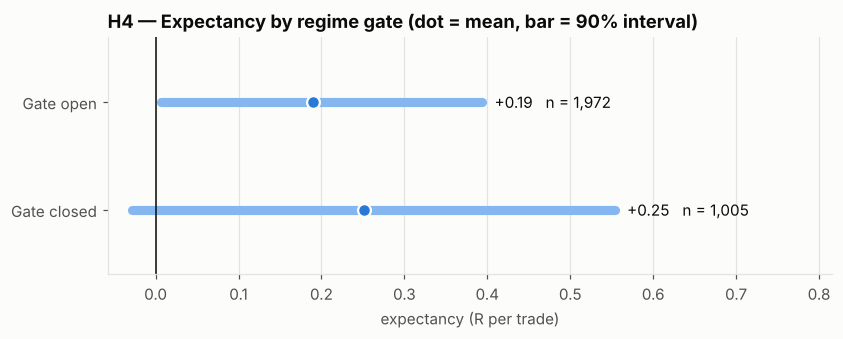

              mean     lo     hi  trades   win %  fwd_10 %
Gate open    0.190  0.006  0.394  1972.0  26.775     2.685
Gate closed  0.251 -0.029  0.554  1005.0  28.657     1.869

Open minus closed: -0.056R, 90% interval -0.417 to +0.290


In [10]:
gate_groups = {"Gate open": passed[passed["gate"]], "Gate closed": passed[~passed["gate"]]}
h4 = pd.DataFrame({name: dict(zip(["mean", "lo", "hi"], interval(g)), trades=len(g),
                              **{"win %": 100 * np.mean(g[R_COL] > 0),
                                 f"{OUTCOME} %": 100 * g[OUTCOME].mean()})
                   for name, g in gate_groups.items()}).T
interval_chart(h4, "H4 — Expectancy by regime gate (dot = mean, bar = 90% interval)")
print(h4.round(3).to_string())

d_h4 = bt.bootstrap_diff(gate_groups["Gate open"], gate_groups["Gate closed"], R_COL, draws=1500)
h4_lo, h4_hi = np.percentile(d_h4, [5, 95])
print(f"\nOpen minus closed: {d_h4.mean():+.3f}R, 90% interval {h4_lo:+.3f} to {h4_hi:+.3f}")

## Step 8 — Robustness

A result that holds only for one setting is not a result. Three checks:
a wider stop, scan dates that do not overlap, and each year on its own.

In [11]:
checks = {}
def high_low(frame, column):
    f = frame.copy()
    f["group"] = f.groupby(level="date")["score"].transform(thirds)
    hi = f.loc[f["group"] == "High score", column].mean()
    lo = f.loc[f["group"] == "Low score", column].mean()
    return hi - lo

other = "R_1.0" if STOP == "0.5" else "R_0.5"
every4 = sorted(set(dates))[::4]
sparse = passed[passed.index.get_level_values("date").isin(every4)]
checks[f"Base case ({R_COL})"] = (passed, R_COL)
checks[f"Other stop ({other})"] = (passed, other)
checks["Non-overlapping dates (every 20 days)"] = (sparse, R_COL)
for year in sorted(set(d.year for d in dates)):
    checks[f"Year {year}"] = (passed[passed.index.get_level_values("date").year == year], R_COL)

rob = pd.DataFrame({name: {"trades": len(f), "expectancy R": f[c].mean(),
                           "win %": 100 * np.mean(f[c] > 0),
                           "score IC": bt.rank_ic(f, "score", c).mean(),
                           "high − low R": high_low(f, c)}
                    for name, (f, c) in checks.items()}).T
print(rob.round(3).to_string())

                                       trades  expectancy R   win %  score IC  high − low R
Base case (R_0.5)                      2977.0         0.211  27.410    -0.008        -0.060
Other stop (R_1.0)                     2977.0         0.219  35.472     0.036        -0.017
Non-overlapping dates (every 20 days)   733.0         0.433  28.513     0.051         0.278
Year 2022                               348.0        -0.136  23.851     0.031        -0.185
Year 2023                               496.0         0.332  30.444    -0.027         0.112
Year 2024                               678.0         0.363  29.499     0.100         0.605
Year 2025                               767.0         0.240  25.163    -0.129        -0.765
Year 2026                               688.0         0.116  27.471     0.003         0.025


## Step 9 — Verdict

Each hypothesis is called **supported** only if the 90% interval of the
difference lies wholly above zero, **contradicted** if wholly below, and
**not shown** otherwise.

In [12]:
def call(lo, hi):
    return "SUPPORTED" if lo > 0 else "CONTRADICTED" if hi < 0 else "NOT SHOWN"

agree = int(h3["agrees"].sum())
strong = h3["t-stat "].astype(float).abs() >= 2
strong_agree = int((strong & h3["agrees"]).sum())
strong_oppose = int((strong & ~h3["agrees"]).sum())
h3_call = ("SUPPORTED" if strong_agree and not strong_oppose else
           "CONTRADICTED" if strong_oppose and not strong_agree else "NOT SHOWN")
verdicts = {
    "H1 filters pick better stocks": (call(h1_lo, h1_hi),
        f"passed minus not passed {d_h1.mean():+.2f}R ({h1_lo:+.2f} to {h1_hi:+.2f})"),
    "H2 higher score, better trade": (call(h2_lo, h2_hi),
        f"high minus low {d_h2.mean():+.2f}R ({h2_lo:+.2f} to {h2_hi:+.2f}); "
        f"IC {ic_ret.mean():+.3f}, t = {bt.ic_summary(ic_ret)['t-stat']:+.1f}"),
    "H3 score inputs point the right way": (
        h3_call,
        f"{agree} of 4 inputs have the expected sign; {int(strong.sum())} of 4 "
        f"reach a t-stat of 2 in either direction"),
    "H4 regime gate helps": (call(h4_lo, h4_hi),
        f"open minus closed {d_h4.mean():+.2f}R ({h4_lo:+.2f} to {h4_hi:+.2f})"),
}
for name, (status, detail) in verdicts.items():
    print(f"{status:13s} {name}\n{'':13s} {detail}")

NOT SHOWN     H1 filters pick better stocks
              passed minus not passed +0.05R (-0.19 to +0.28)
NOT SHOWN     H2 higher score, better trade
              high minus low -0.06R (-0.33 to +0.23); IC -0.037, t = -1.6
NOT SHOWN     H3 score inputs point the right way
              0 of 4 inputs have the expected sign; 0 of 4 reach a t-stat of 2 in either direction
NOT SHOWN     H4 regime gate helps
              open minus closed -0.06R (-0.42 to +0.29)


## What this notebook shows

The figures below are for the saved history (15 Nov 2021 to 13 Nov 2026,
221 scan dates, 2,977 trades on stocks that passed the scan, stop 0.5 ADR).

1. **The setup score does not rank candidates.** High-score trades made
   +0.17R, low-score trades +0.23R. The difference, −0.06R, has a 90%
   interval of −0.33 to +0.23. The rank correlation of score with the
   10-day return is −0.04 (t = −1.6).
2. **The filters add little.** Stocks that passed made +0.21R against
   +0.17R for all high-ADR stocks. The difference is +0.05R with an
   interval of −0.19 to +0.28. Leaders that failed the trend filter made
   the same +0.21R as those that passed.
3. **No score input is reliable.** None of the four inputs has the
   expected sign against the 10-day return, and none reaches a t-stat of 2
   either way. Tightness and volume dry-up lean the wrong way: stocks with
   wider recent ranges and more recent volume did slightly better.
4. **The regime gate is not shown to help.** Gate open +0.19R, gate closed
   +0.25R; interval of the difference −0.42 to +0.29.
5. **The edge is far below the borrowed one.** Win rate 27% (borrowed
   23%), average winner 3.5R (borrowed 8R), expectancy +0.21R (borrowed
   +1.07R). And +0.21R is before survivorship bias, costs and slippage.
6. **Results swing by year.** Expectancy runs from −0.14R (2022) to
   +0.36R (2024). The high-minus-low score gap is +0.61R in 2024 and
   −0.77R in 2025: noise, not signal.

**What follows for the lab.** The allocator's objective and the daily
report's ranking rest on a score with no demonstrated value. Until a score
passes this test, treat the candidate list as unordered: the scan narrows
the field, and the choice among candidates is yours, from the charts.
The Monte Carlo and Bayesian phases do not depend on the score.

## What the backtest does not do

- **Survivorship bias.** The universe is today's list. Stocks that failed
  or were delisted are missing, and today's winners are over-represented.
  All expectancy levels are too high.
- **Entry at the open.** Your rules enter on an intraday breakout near the
  low of the day, with the stop at that low. Daily bars cannot test that.
  The real method may do better or worse than this stand-in.
- **No costs, no slippage,** and stops fill exactly at the stop price.
- **Trades overlap.** The same stock can pass on consecutive scan dates,
  and results on nearby dates share the same market move. The bootstrap by
  date reduces this problem and does not remove it.
- **One market period.** About four years of scan dates.
- **No portfolio.** Every candidate is traded. The two-slot and cash limits
  are not applied.

## Do not just re-fit the weights

It is tempting to change the score weights until the backtest looks good.
That fits the past, not the future. If you change the score, choose the
change on the first half of the history and check it once on the second
half, which you have not looked at.

## Exercises

1. Set `STOP = "1.0"`. Which verdicts change?
2. Set `OUTCOME = "fwd_20"`. Does any score input gain a t-stat beyond 2?
3. In Step 5, split into two groups (halves) in place of three. Same answer?
4. In `backtest.py`, change `simulate_trade` to trail under the 21-day EMA
   (pass a different `ema`). How do win rate and average winner move?
5. Split the panel at its middle date. Compute the IC of `tightness` on
   each half. Is the sign stable?
6. Feed the backtest's win rate and average winner into Phase 1
   (`WIN_RATE`, `AVG_WIN_R`). What does the fan chart say now?